# Titanic 생존 예측: 특성 공학 비교 과제

**빅데이터분석 01분반 · 실제 실행 결과를 포함한 재현용 노트북**

891명 / 12개 설정 × 2개 모델 / 동일 5-fold CV / 179명 최종 평가.
분석의 전체 구현은 함께 제공된 `analysis.py`입니다. 이 노트북은 기본적으로 저장된 실제 실험 결과를 읽습니다.
아래 `RECOMPUTE=True`를 설정하면 모델 학습부터 다시 수행합니다.

목표: 결측값 대체, 인코딩, 스케일링, 파생 변수와 변수 선택이 모델에 미치는 영향을 비교합니다.
생존(1)을 양성으로 정의하고 CV F1으로 모델을 선택합니다. 최종 평가 데이터는 설정 선택에 사용하지 않습니다.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import analysis

ROOT = Path(analysis.__file__).resolve().parent
RESULTS = ROOT / 'results'
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)


## 1. 데이터 준비와 검증 분리
원본 CSV는 공개 Titanic 데이터 미러입니다. `load_data()`가 SHA-256을 검증합니다.

In [2]:
df, sha = analysis.load_data()
print('데이터 shape:', df.shape)
print('원본 SHA-256:', sha)
display(df.head())
display(pd.read_csv(RESULTS / 'data_dictionary.csv'))


데이터 shape: (891, 12)
원본 SHA-256: 4a437fde05fe5264e1701a7387ac6fb75393772ba38bb2c9c566405af5af4bd7


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,column,dtype,missing_all,missing_all_pct,missing_train,missing_train_pct,unique_all
0,PassengerId,int64,0,0.000000,0,0.000000,891
1,Survived,int64,0,0.000000,0,0.000000,2
2,Pclass,int64,0,0.000000,0,0.000000,3
3,Name,str,0,0.000000,0,0.000000,891
4,Sex,str,0,0.000000,0,0.000000,2
5,Age,float64,177,19.865320,137,19.241573,88
6,SibSp,int64,0,0.000000,0,0.000000,7
7,Parch,int64,0,0.000000,0,0.000000,7
8,Ticket,str,0,0.000000,0,0.000000,681
9,Fare,float64,0,0.000000,0,0.000000,248


In [3]:
manifest = json.loads((RESULTS / 'split_manifest.json').read_text(encoding='utf-8'))
train = df[df.PassengerId.isin(manifest['train_ids'])]
print('학습:', len(train), '| 최종 평가:', len(manifest['test_ids']))
print('학습 타깃 분포:')
display(train.Survived.value_counts().sort_index().rename('count'))


학습: 712 | 최종 평가: 179
학습 타깃 분포:


Survived
0    439
1    273
Name: count, dtype: int64

## 2. EDA

그래프는 학습 712명으로만 작성했습니다. 전체 데이터의 결측 수는 위의 데이터 설명 표와 구분합니다.
Cabin은 학습에서 77.53%가 비어 제외했고, Age와 Embarked는 Pipeline 내부에서 처리합니다.
IQR 이상치는 통계적 탐지값이며 잘못된 기록이라고 단정하지 않고 보존했습니다.


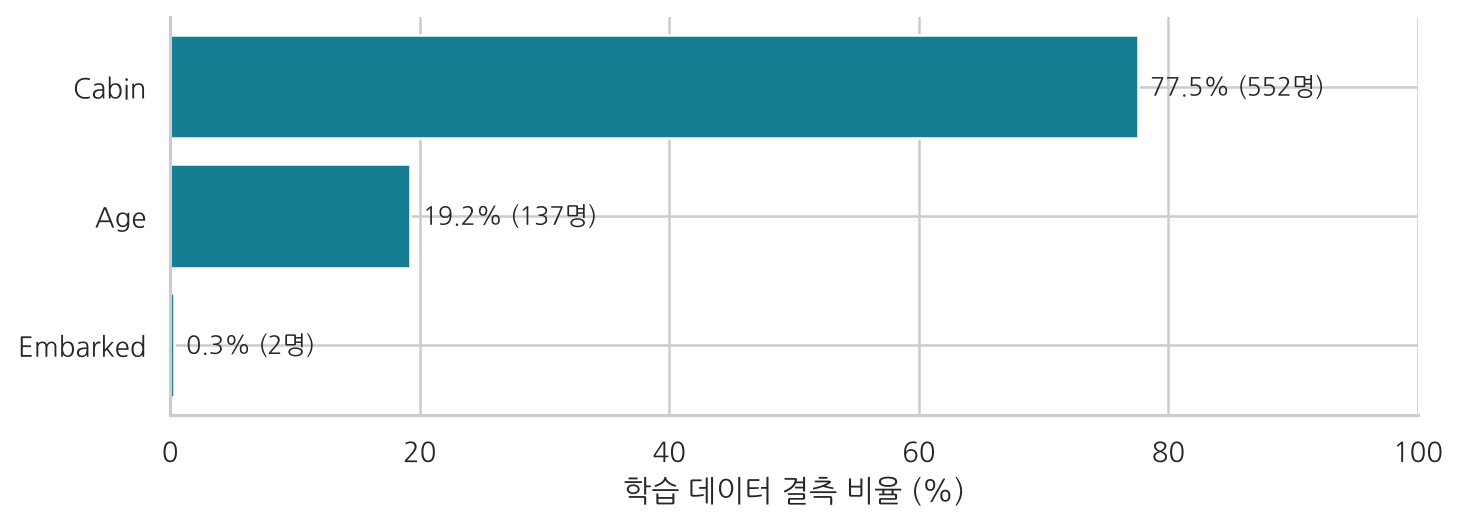

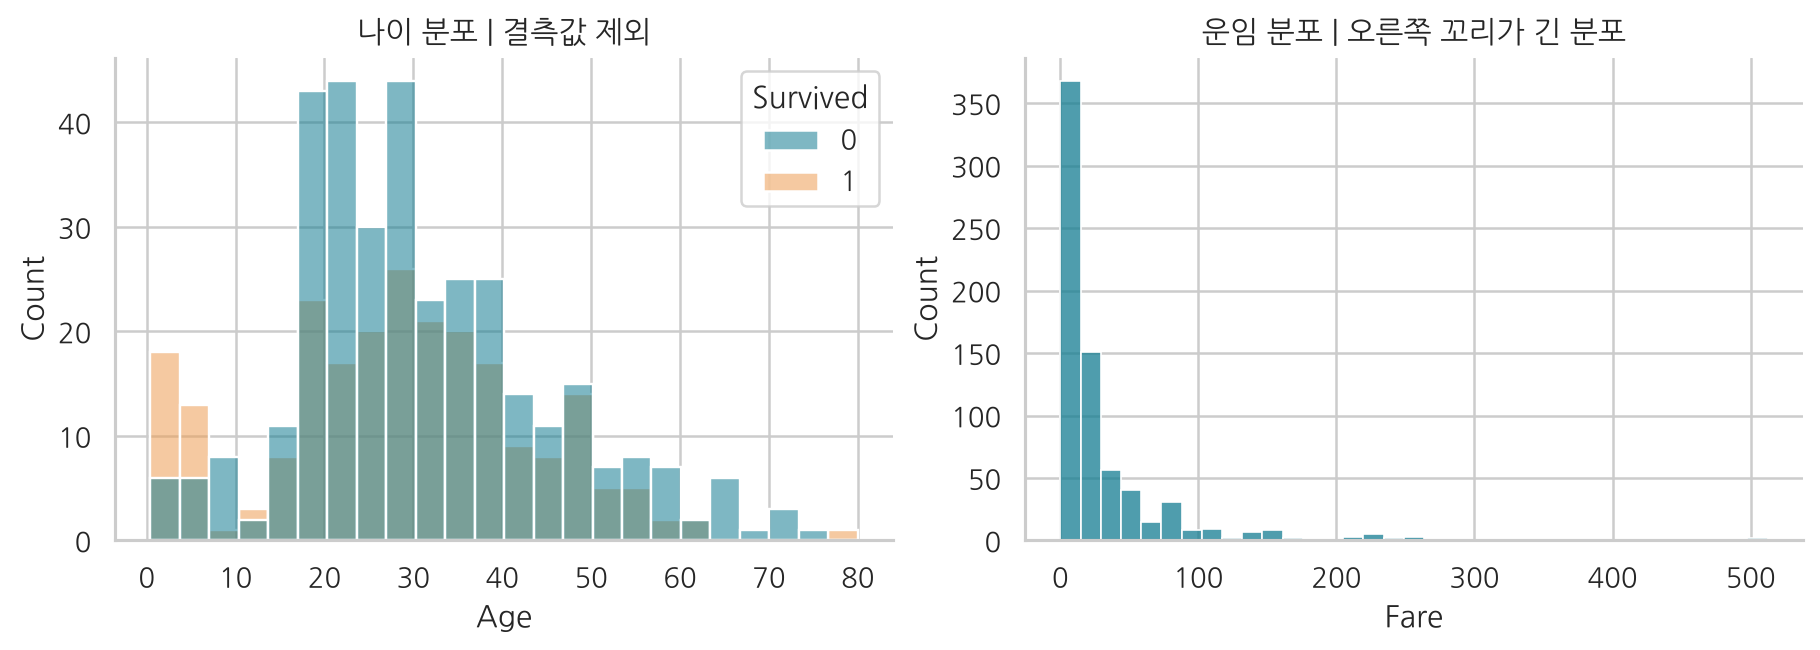

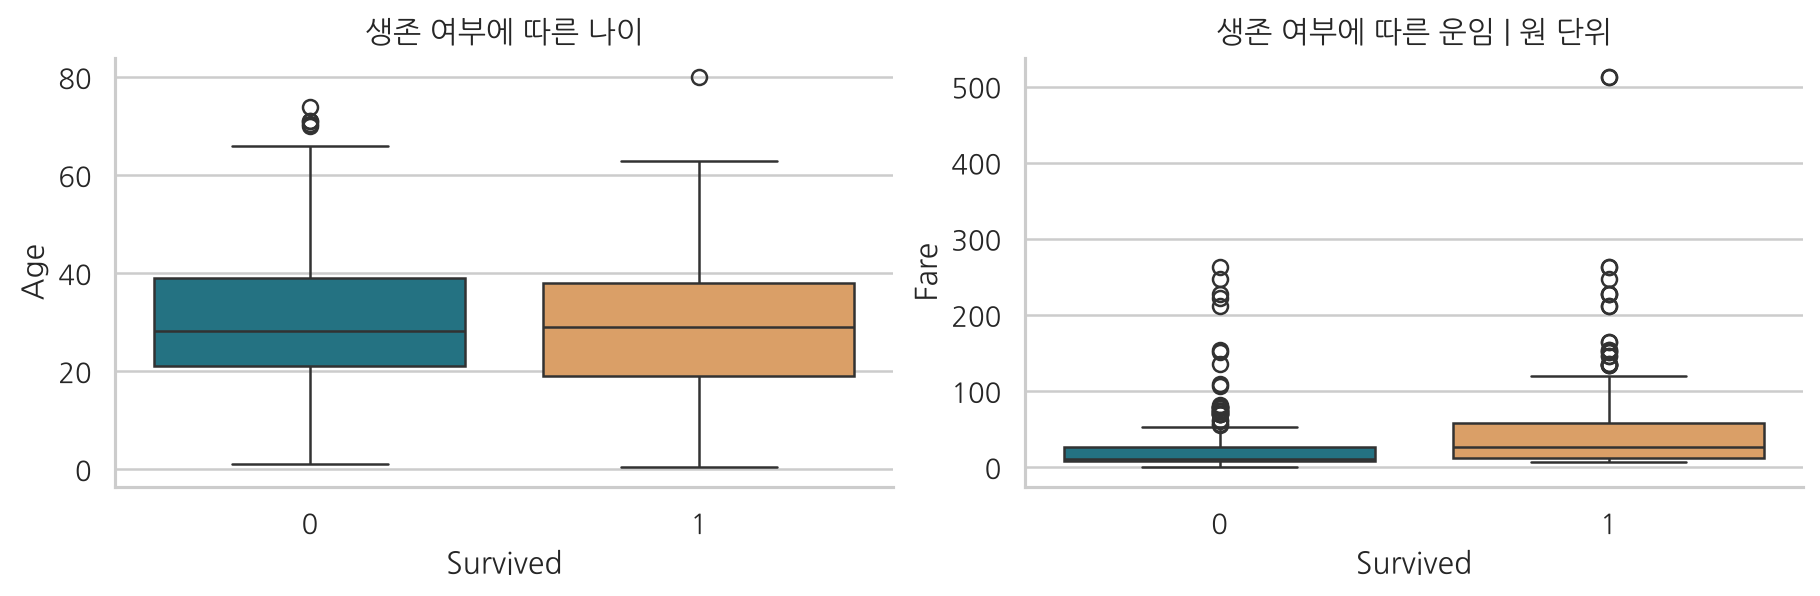

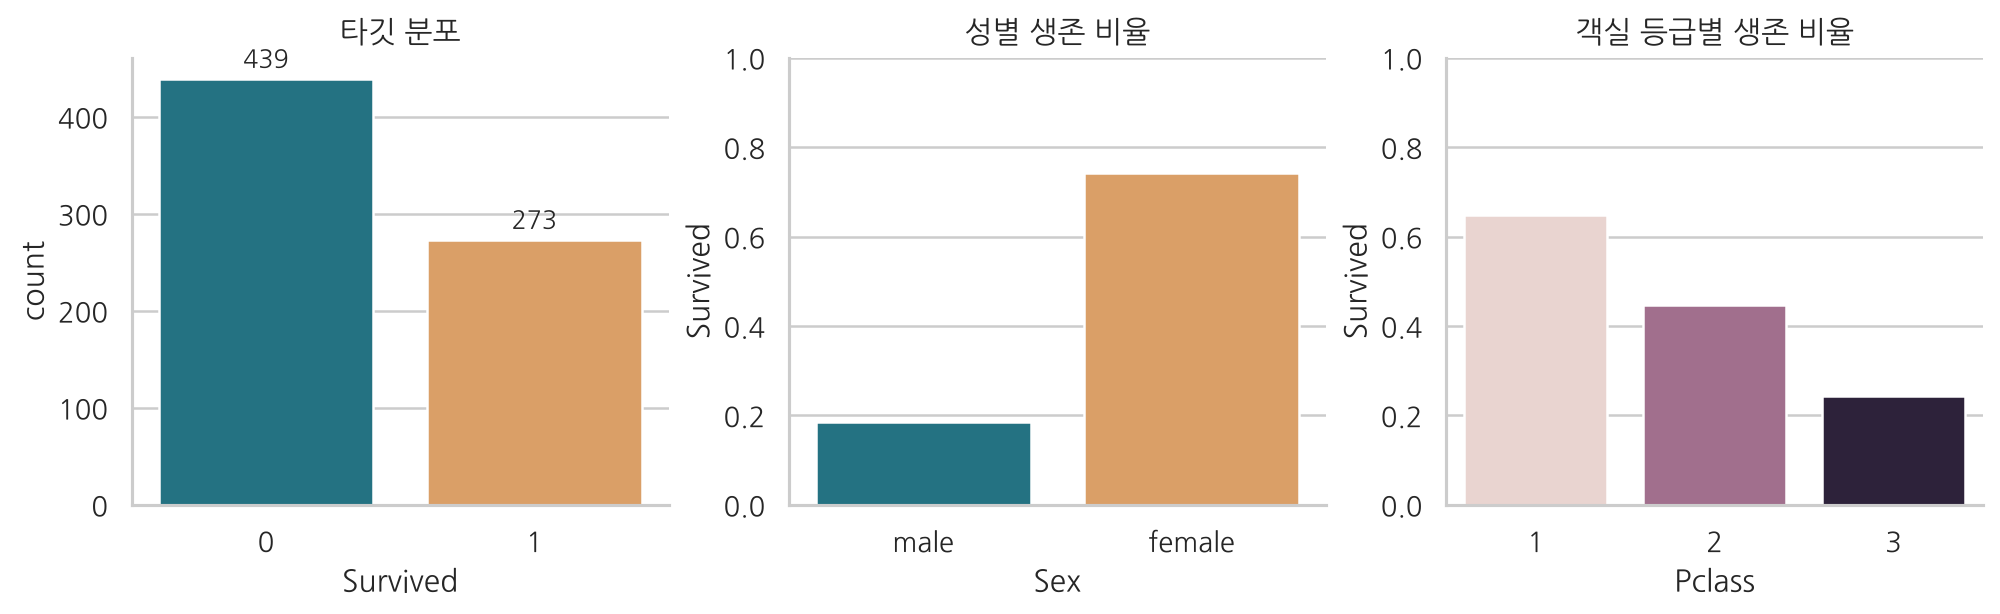

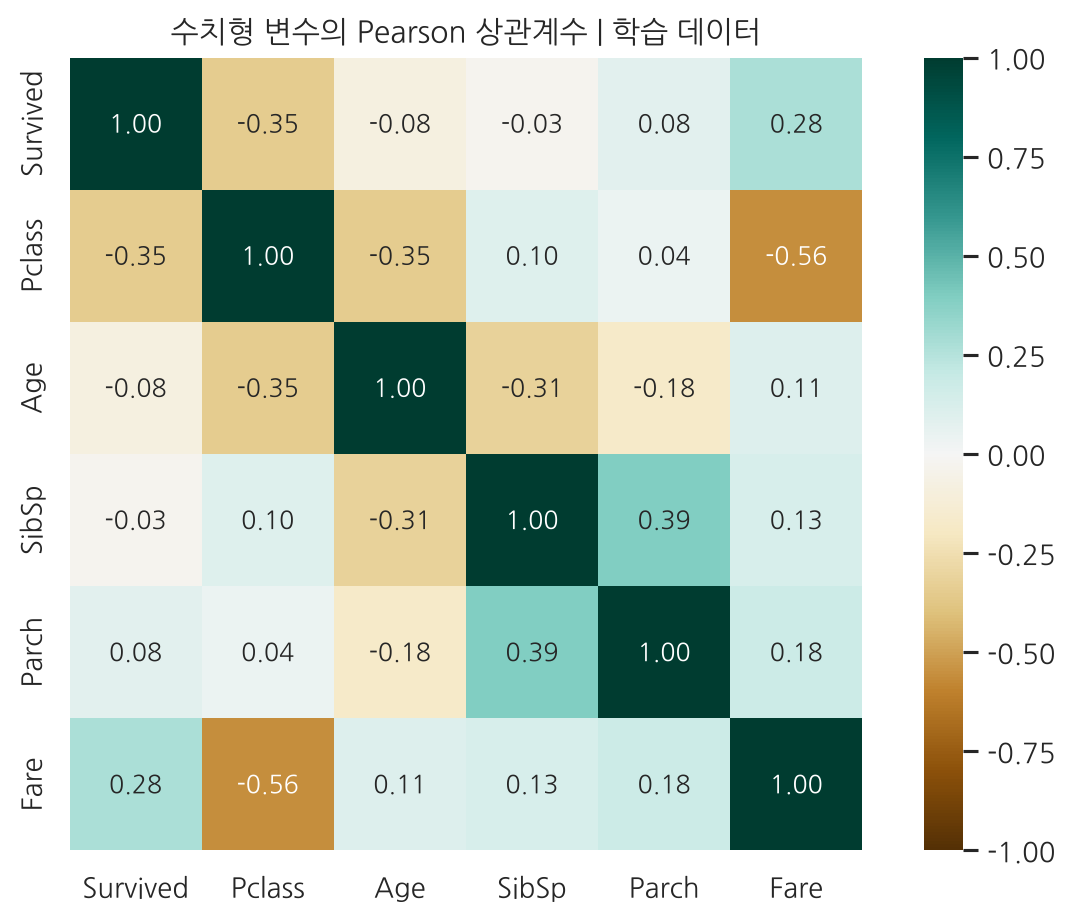

,feature,q1,q3,lower,upper,outliers,outlier_pct,min,max
0,Age,21.0000,39.0,-6.0000,66.0000,6,0.842697,0.42,80.0000
1,Fare,7.8958,31.0,-26.7605,65.6563,91,12.780899,0.00,512.3292
2,SibSp,0.0000,1.0,-1.5000,2.5000,33,4.634831,0.00,8.0000
3,Parch,0.0000,0.0,0.0000,0.0000,170,23.876404,0.00,6.0000


In [4]:
for name in ['05_missingness.png', '01_histograms.png', '02_boxplots.png',
             '04_target_and_groups.png', '03_heatmap.png']:
    display(Image(filename=str(ROOT / 'figures' / name), width=850))
display(pd.read_csv(RESULTS / 'outliers_train.csv'))


## 3. 특성 공학 파이프라인

- 수치 결측값: Mean / Median / Most Frequent. 범주형 결측값은 최빈값으로 고정.
- 인코딩: OneHotEncoder / OrdinalEncoder(특성별 정수 매핑).
- 수치 스케일: Standard / MinMax / Robust / 미적용.
- 파생 변수: FamilySize=SibSp+Parch+1, FarePerPerson=Fare/FamilySize, IsAlone, 이름에서 추출한 Title.
- 변수 선택: RF 불순도 중요도 상위 10개. 각 학습 fold에서만 적합.
- 모델: Logistic Regression, Random Forest.

Base는 결측이 없는 Pclass/SibSp/Parch/Fare만 사용하는 무전처리 기준선입니다.
Base와 다른 실험의 차이는 정보량 차이도 포함합니다. 한 처리의 효과는 Ref를 기준으로 한 통제 비교에서 판단합니다.


In [5]:
display(pd.DataFrame(analysis.configs()).fillna(False))
reference = next(c for c in analysis.configs() if c['name'] == 'Ref')
pipeline = analysis.make_pipeline(reference, 'RF')
print(pipeline)


,name,imputation,encoding,scaling,selection,engineered,baseline
0,Base,none,none,none,False,False,True
1,Exp-1,mean,onehot,standard,False,True,False
2,Exp-2,median,ordinal,minmax,True,True,False
3,Exp-3,most_frequent,onehot,robust,True,True,False
4,Ref,median,onehot,standard,False,True,False
5,No-FE,median,onehot,standard,False,False,False
6,Ordinal,median,ordinal,standard,False,True,False
7,MinMax,median,onehot,minmax,False,True,False
8,Robust,median,onehot,robust,False,True,False
9,No-Scale,median,onehot,none,False,True,False


Pipeline(steps=[('features', TitanicFeatures()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare', 'SibSp',
                                                   'Parch', 'FamilySize',
                                                   'FarePerPerson',
                                                   'IsAlone']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent'

## 4. 실험 실행 또는 저장 결과 읽기
전체 학습을 재실행하려면 다음 변수만 True로 변경하세요. 재실행은 결과 CSV와 그림을 갱신합니다.

In [6]:
RECOMPUTE = False
if RECOMPUTE:
    summary = analysis.run()
else:
    summary = json.loads((RESULTS / 'summary.json').read_text(encoding='utf-8'))
    print('저장된 실제 실행 결과를 사용합니다:', summary['executed_utc'])
print('난수 시드:', summary['seed'])
print('실행 환경:', summary['versions'])


저장된 실제 실행 결과를 사용합니다: 2026-11-11T18:11:54.907515+00:00
난수 시드: 42
실행 환경: {'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'shap': '0.54.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'reportlab': '5.0.1', 'pypdf': '6.17.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


## 5. 필수 조합과 두 모델 비교
다음 값은 동일 5-fold CV 평균입니다. 표의 SD는 fold 간 표준편차이며 신뢰구간이 아닙니다.

,experiment,model,Accuracy,Precision,Recall,F1,F1_sd,ROC_AUC
0,Base,LR,0.6952,0.6498,0.4542,0.5333,0.0114,0.7060
1,Base,RF,0.7430,0.7448,0.5090,0.6012,0.0408,0.7630
2,Exp-1,LR,0.8231,0.7867,0.7437,0.7633,0.0282,0.8665
3,Exp-1,RF,0.8160,0.8013,0.6958,0.7437,0.0263,0.8787
4,Exp-2,LR,0.8062,0.7725,0.7071,0.7371,0.0264,0.8513
5,Exp-2,RF,0.8203,0.8078,0.7030,0.7500,0.0302,0.8831
6,Exp-3,LR,0.8118,0.7692,0.7288,0.7479,0.0532,0.8572
7,Exp-3,RF,0.8301,0.8096,0.7325,0.7680,0.0265,0.8842


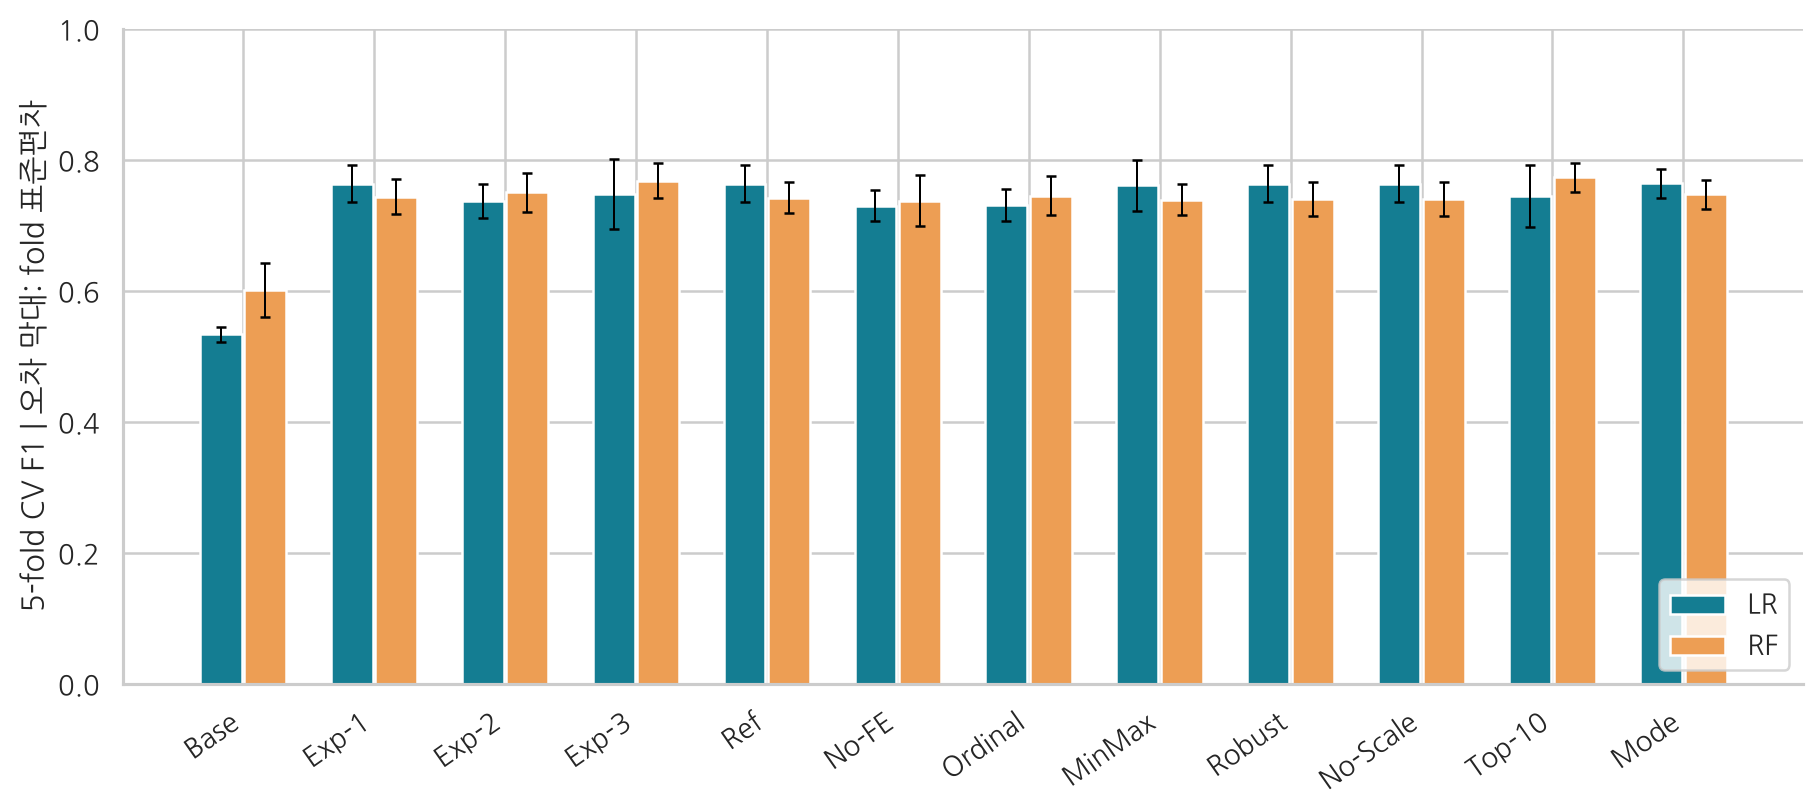

In [7]:
cv = pd.read_csv(RESULTS / 'cv_results.csv')
columns = ['experiment', 'model', 'Accuracy', 'Precision', 'Recall', 'F1', 'F1_sd', 'ROC_AUC']
display(cv[cv.experiment.isin(['Base', 'Exp-1', 'Exp-2', 'Exp-3'])][columns].round(4))
display(Image(filename=str(ROOT / 'figures/06_cv_comparison.png'), width=950))


## 6. 통제 비교

Ref = Median + One-Hot + Standard + 파생 변수 + 변수 선택 없음.
표의 delta_f1은 변경 설정 - Ref이며, 한 요소만 바꿨습니다.
동일 fold의 대응 차이와 그 SD를 저장했습니다. 이 값으로 통계적 유의성을 주장하지 않습니다.


In [8]:
display(cv[columns].round(4))
controlled = pd.read_csv(RESULTS / 'controlled_comparisons.csv')
display(controlled.round(4))


,experiment,model,Accuracy,Precision,Recall,F1,F1_sd,ROC_AUC
0,Base,LR,0.6952,0.6498,0.4542,0.5333,0.0114,0.7060
1,Base,RF,0.7430,0.7448,0.5090,0.6012,0.0408,0.7630
2,Exp-1,LR,0.8231,0.7867,0.7437,0.7633,0.0282,0.8665
3,Exp-1,RF,0.8160,0.8013,0.6958,0.7437,0.0263,0.8787
4,Exp-2,LR,0.8062,0.7725,0.7071,0.7371,0.0264,0.8513
5,Exp-2,RF,0.8203,0.8078,0.7030,0.7500,0.0302,0.8831
6,Exp-3,LR,0.8118,0.7692,0.7288,0.7479,0.0532,0.8572
7,Exp-3,RF,0.8301,0.8096,0.7325,0.7680,0.0265,0.8842
8,Ref,LR,0.8231,0.7867,0.7437,0.7633,0.0282,0.8660
9,Ref,RF,0.8146,0.7973,0.6958,0.7421,0.0240,0.8786


,comparison,model,experiment,delta_f1,delta_sd
0,Mean vs Median,LR,Exp-1,0.0000,0.0000
1,Mode vs Median,LR,Mode,0.0010,0.0071
2,Ordinal vs OneHot,LR,Ordinal,-0.0319,0.0093
3,MinMax vs Standard,LR,MinMax,-0.0020,0.0173
4,Robust vs Standard,LR,Robust,0.0000,0.0000
5,No scale vs Standard,LR,No-Scale,0.0000,0.0000
6,Top10 vs All,LR,Top-10,-0.0192,0.0316
7,No FE vs FE,LR,No-FE,-0.0331,0.0127
8,Mean vs Median,RF,Exp-1,0.0016,0.0035
9,Mode vs Median,RF,Mode,0.0050,0.0069


## 7. 변수 선택과 설명

20개 변환 특성 중 상위 10개를 선택했습니다. 아래 목록은 학습 데이터 전체 재적합 결과이며,
CV fold에서는 다른 변수가 선택될 수 있습니다.
순열 중요도는 최종 평가 이후 설명을 위해서만 계산했고 재선택에 사용하지 않았습니다.

과적합 여부는 같은 fold의 학습 F1과 검증 F1의 격차(`F1_gap` = 학습 - 검증)로 확인합니다.


,feature,importance,selected
0,Title_Mr,0.1668,True
1,Sex_female,0.1554,True
2,Sex_male,0.1237,True
3,FarePerPerson,0.1022,True
4,Fare,0.0912,True
5,Age,0.0628,True
6,Pclass_3,0.0587,True
7,FamilySize,0.0397,True
8,Title_Miss,0.0385,True
9,Title_Mrs,0.0314,True


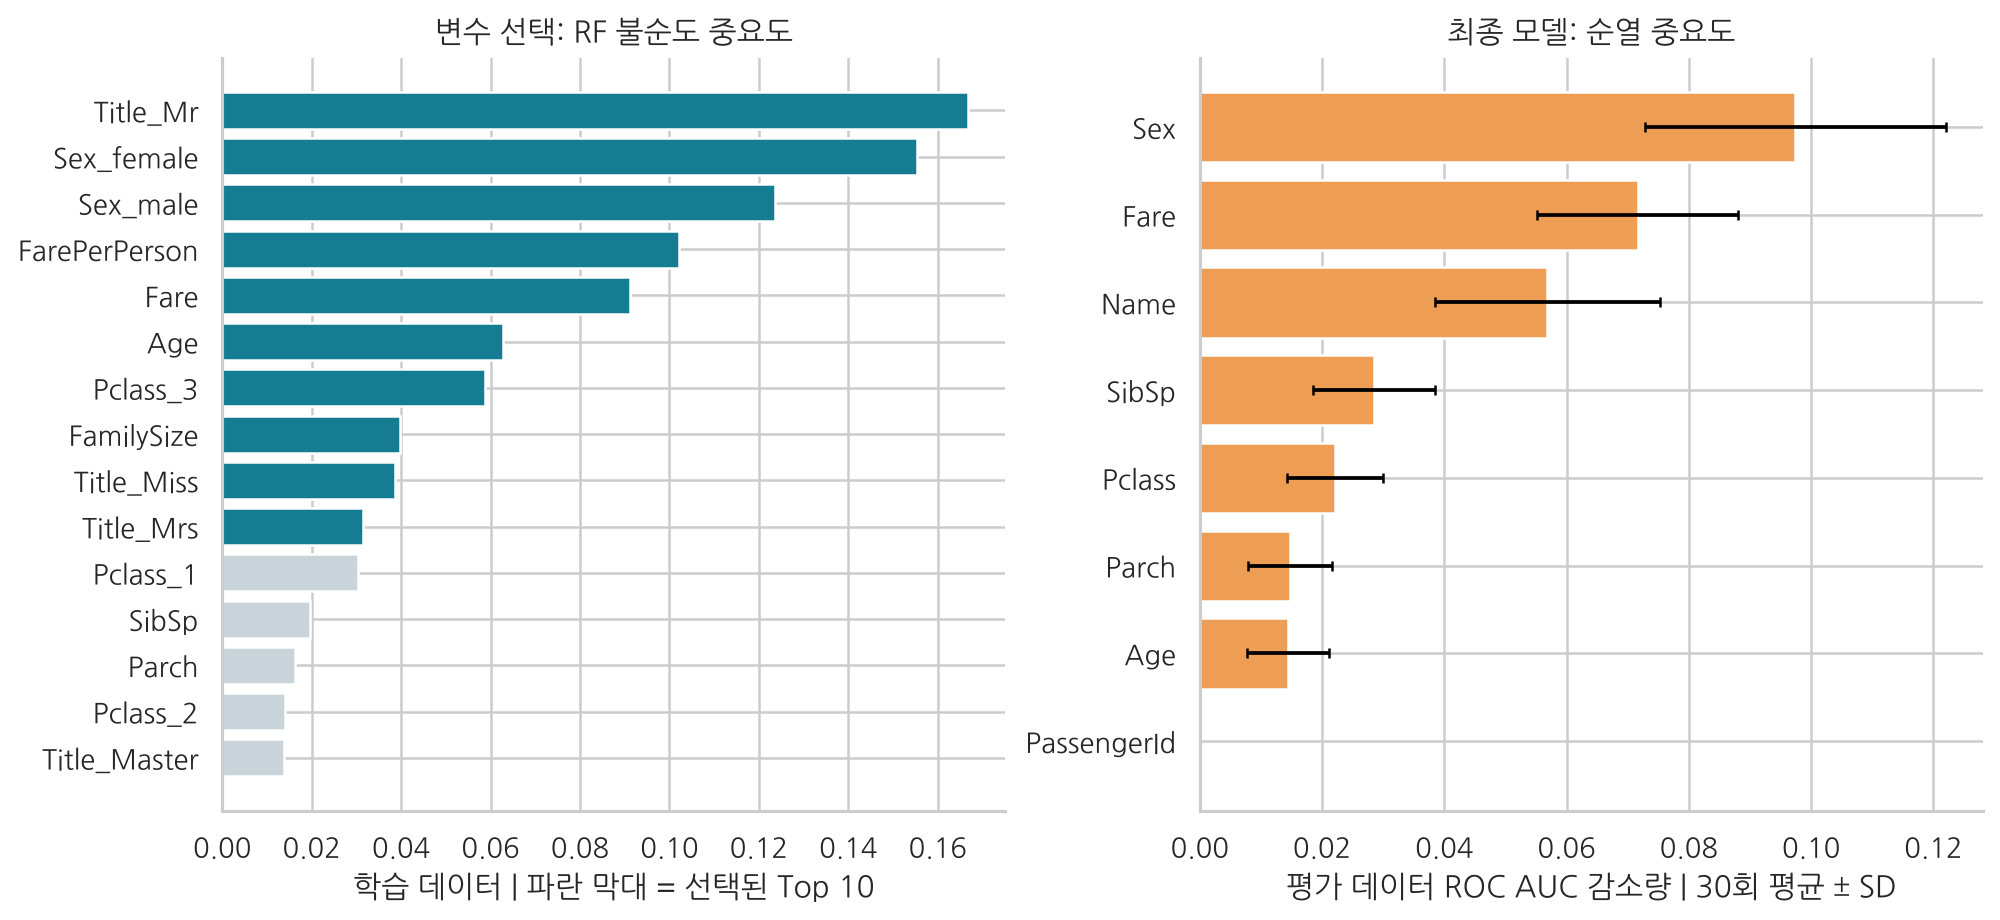

변수 선택 전(Ref) / 후(Top-10)의 학습-검증 F1 격차


,experiment,model,F1_train,F1,F1_gap,F1_gap_sd
8,Ref,LR,0.7695,0.7633,0.0063,0.0340
9,Ref,RF,0.8399,0.7421,0.0978,0.0268
20,Top-10,LR,0.7504,0.7440,0.0064,0.0624
21,Top-10,RF,0.8569,0.7731,0.0838,0.0317


In [9]:
display(pd.read_csv(RESULTS / 'feature_selection.csv').round(4))
display(Image(filename=str(ROOT / 'figures/08_feature_importance.png'), width=1000))
print('변수 선택 전(Ref) / 후(Top-10)의 학습-검증 F1 격차')
display(cv[cv.experiment.isin(['Ref', 'Top-10'])][['experiment', 'model', 'F1_train', 'F1', 'F1_gap', 'F1_gap_sd']].round(4))


## 8. GridSearchCV와 최종 평가

최고 CV F1 설정을 선택한 뒤 학습 데이터 안에서 GridSearchCV를 수행했습니다.
여러 설정을 같은 fold로 고른 CV 점수는 낙관적일 수 있습니다. 최종 성능은 별도로 남겨 둔 179명에서 평가했습니다.
Bootstrap 구간은 평가 표본을 2,000회 재표집한 분위수이며 모델 선택 및 가족 의존성은 반영하지 않습니다.


선택 설정 / 모델: Top-10 RF
최적 파라미터: {'model__max_depth': 8, 'model__min_samples_leaf': 2}
튜닝 후 CV F1: 0.7831913694684183


,score,CI95_low,CI95_high
Accuracy,0.8268,0.7709,0.8827
Precision,0.8065,0.7000,0.8983
Recall,0.7246,0.6129,0.8333
F1,0.7634,0.6772,0.8395
ROC_AUC,0.8522,0.7827,0.9126


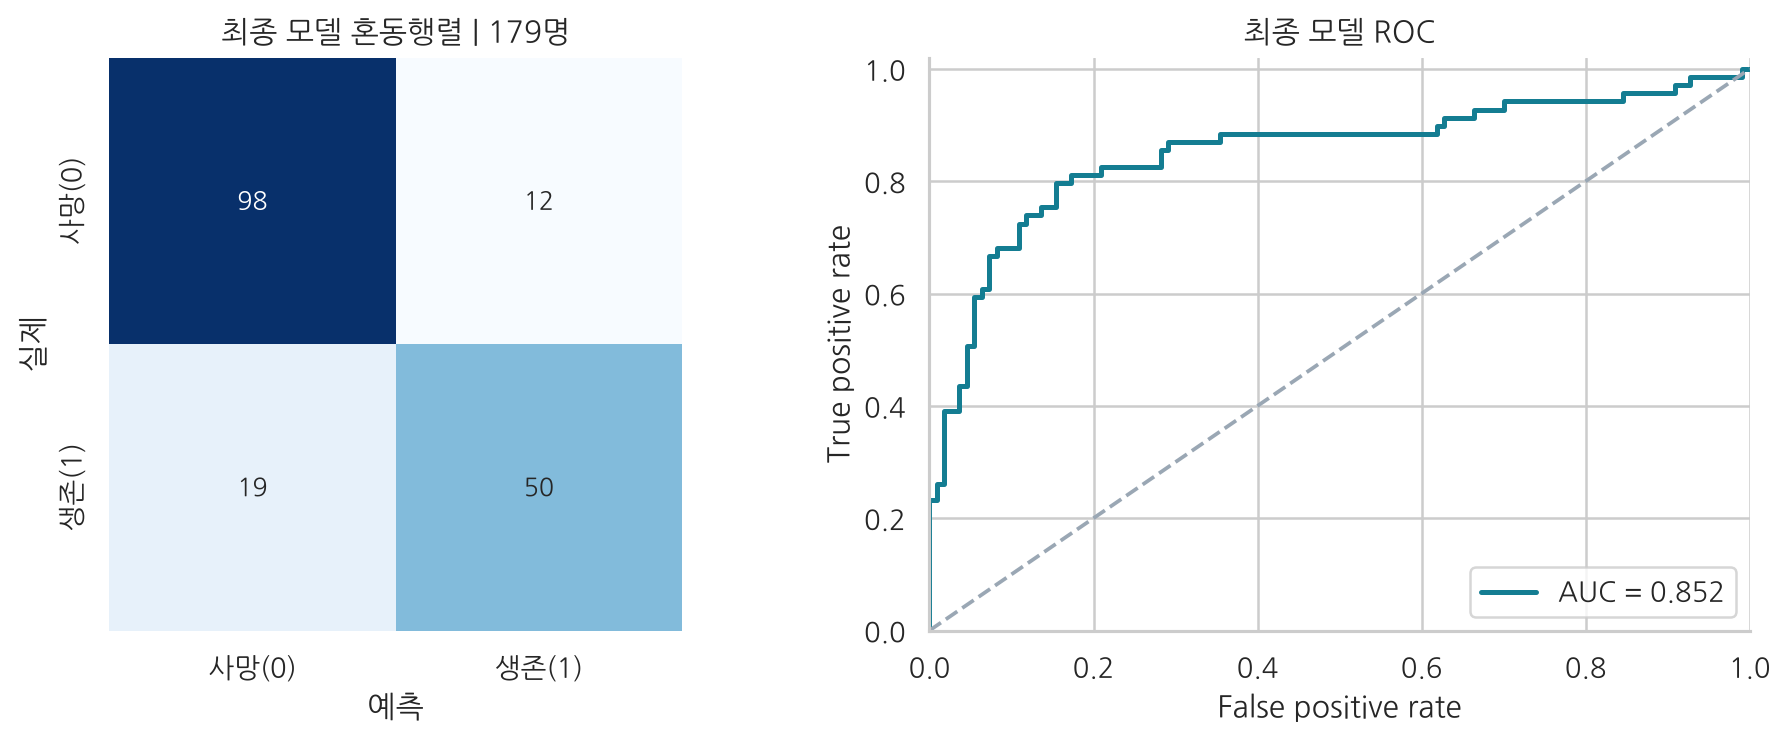

In [10]:
print('선택 설정 / 모델:', summary['selected_experiment'], summary['selected_model'])
print('최적 파라미터:', summary['best_params'])
print('튜닝 후 CV F1:', summary['tuned_cv_f1'])
metrics = pd.DataFrame({'score': summary['holdout'],
                        'CI95_low': {k:v[0] for k,v in summary['holdout_ci95'].items()},
                        'CI95_high': {k:v[1] for k,v in summary['holdout_ci95'].items()}})
display(metrics.round(4))
display(Image(filename=str(ROOT / 'figures/07_holdout_evaluation.png'), width=900))


## 9. SHAP 기반 설명

최종 Random Forest에 TreeExplainer를 적용해, 선택된 10개 변수가 평가 데이터 179명의 생존(1) 예측 확률에 준 기여를 계산했습니다.
`mean_abs_shap`이 클수록 예측에 미친 영향이 큽니다. `value_shap_corr`은 변수 값과 SHAP 값의 상관으로, 양수면 평가 표본에서 높은 값이 생존 예측에 양의 기여를 하는 경향을 보였다는 뜻입니다(항상 같은 방향이라는 보장은 아닙니다).
평가 완료 후 설명에만 사용했습니다.


기준값(평균 예측 확률): 0.3835


,feature,mean_abs_shap,mean_shap,value_shap_corr
0,Title_Mr,0.0947,0.0155,-0.9790
1,Sex_male,0.0787,-0.0056,-0.9695
2,FarePerPerson,0.0736,-0.0035,0.4530
3,Sex_female,0.0631,-0.0050,0.9679
4,Pclass_3,0.0371,0.0046,-0.7300
5,Fare,0.0314,0.0050,0.4335
6,Age,0.0285,-0.0036,-0.7287
7,FamilySize,0.0218,0.0038,-0.5780
8,Title_Mrs,0.0116,-0.0051,0.9472
9,Title_Miss,0.0082,-0.0008,0.7854


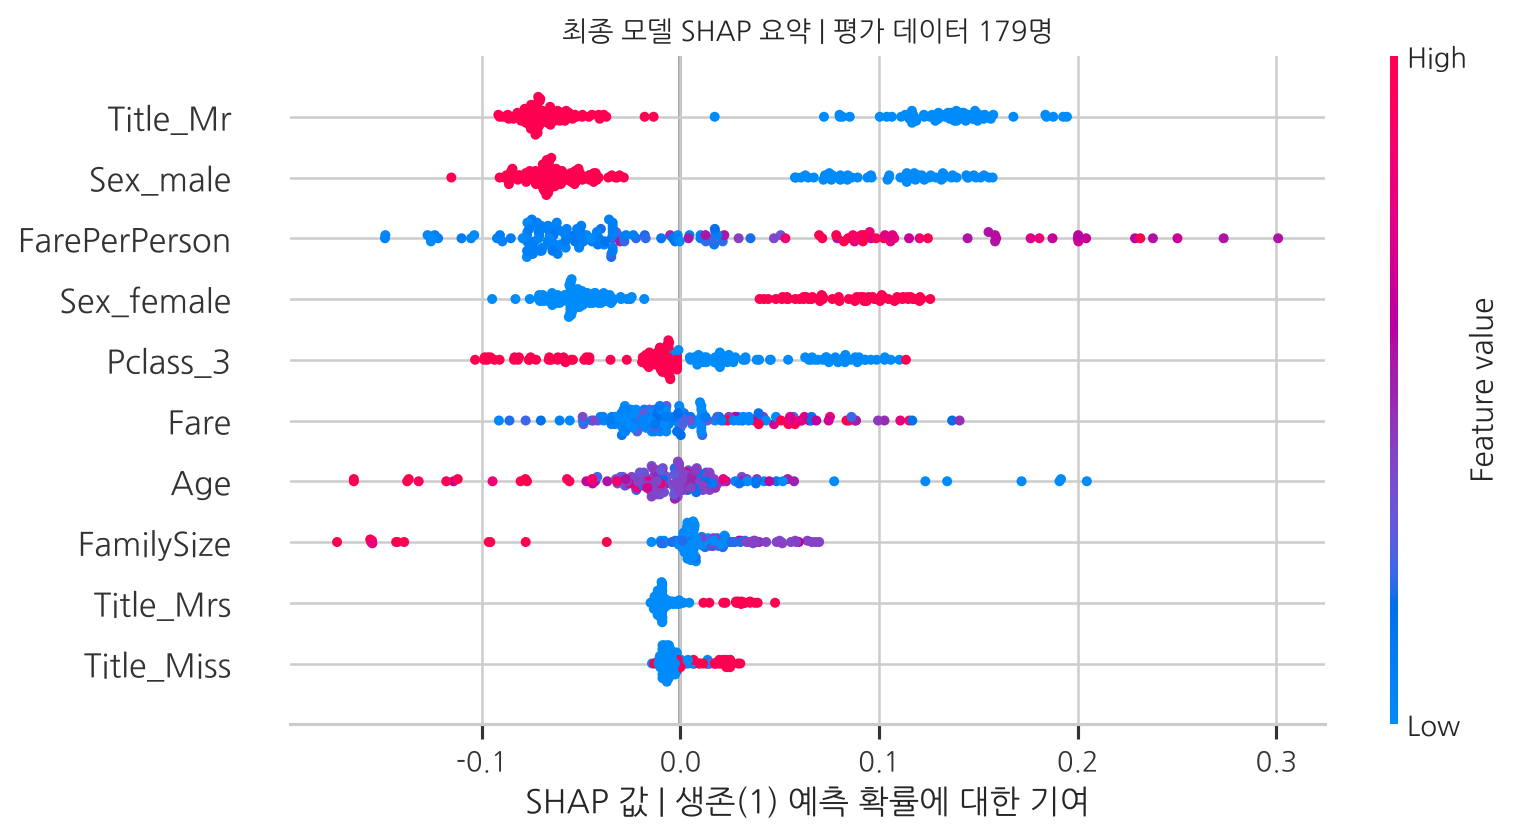

In [11]:
print('기준값(평균 예측 확률):', round(summary['shap']['base_value'], 4))
display(pd.read_csv(RESULTS / 'shap_importance.csv').round(4))
display(Image(filename=str(ROOT / 'figures/09_shap_summary.png'), width=900))


## 10. 결론

1. **전처리의 우열은 모델에 따라 달랐습니다.** RF에서는 Top 10 선택이 CV F1을 약 3.10%p 높였지만 LR은 약 1.92%p 낮아졌습니다.
2. **One-Hot이 항상 우수한 것은 아닙니다.** LR에서는 정수 매핑보다 좋았고 RF에서는 정수 매핑이 소폭 높았습니다.
3. **변수 선택은 RF에서만 과적합을 조금 줄였습니다.** RF의 학습-검증 F1 격차는 9.78%p → 8.38%p로 줄고 검증 F1도 올랐습니다. LR은 격차가 0.63%p → 0.64%p로 그대로였고 검증 F1은 낮아졌습니다.
4. **스케일링 차이는 작았습니다.** LR의 Standard/Robust/미적용 F1은 같았고, MinMax는 약간 낮았습니다.
5. **파생 변수 4개 묶음의 효과:** LR F1 +3.31%p, RF +0.45%p. 개별 변수 효과는 분리하지 않았습니다. SHAP에서도 파생 변수 FarePerPerson이 3위로 원본 Fare보다 기여가 컸습니다.

최종 Random Forest의 평가 정확도 **82.68%**, F1 **0.7634**, ROC AUC **0.8522**입니다.
작은 단일 평가 표본, 가족/티켓의 그룹 분할 미수행, 여러 설정을 탐색한 선택 편향은 한계입니다.

## 출처와 제출

- [Kaggle Titanic](https://www.kaggle.com/competitions/titanic/data)
- [사용 CSV 미러](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv)
- [scikit-learn 혼합형 전처리](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [scikit-learn 데이터 누수 방지](https://scikit-learn.org/stable/common_pitfalls.html)

PDF, 코드, 원본 CSV, 전체 실험표를 함께 제공합니다.
